# DrugScope AI — Task 3: Exploratory Data Analysis
## Notebook 02 — Phase 2: Data quality analysis
**Mini Project in Machine Learning · kinase inhibitors from ChEMBL (raw data, 5 files)**

| Step | Question | Output |
|---|---|---|
| **3. Missing values** | Where is data missing, how much, and why? | Missing values report |
| **4. Duplicate analysis** | Are there repeated rows, IDs, structures or molecule–target records? | Duplicate report |
| **5. Invalid and inconsistent values** | Are there unexpected values, wrong types, impossible numbers, or inconsistent categories and units? | Data quality issues report |

This notebook **only observes and documents**: no dataset is cleaned or modified. The three reports are saved as CSV files in `data/reports/` (documentation only). Each problem found comes with a proposed action for the preprocessing task.

## 0. Setup
We load the five raw datasets (`mol`, `act`, `ind`, `mech`, `tgt`) and prepare a folder for the reports.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.colors import ListedColormap
from eda_utils import load_raw, RAW

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)

mol, act, ind, mech, tgt = load_raw()
files = {"molecules": mol, "activities": act, "indications": ind, "mechanisms": mech, "targets": tgt}

REPORT_DIR = RAW.parent / "reports"
REPORT_DIR.mkdir(exist_ok=True)
print(RAW, "|", {k: v.shape for k, v in files.items()})

../data/raw | {'molecules': (407, 15), 'activities': (15655, 11), 'indications': (2864, 4), 'mechanisms': (610, 5), 'targets': (548, 4)}


**Conclusion:** the five files load with the expected shapes (molecules 407×15, activities 15 655×11, indications 2 864×4, mechanisms 610×5, targets 548×4).

---
# Step 3 — Missing values
Objective: count the missing values, compute their percentage, visualize them and identify the columns concerned. The goal is not only to count but to understand **why** values are missing, because the reason decides what to do with them.

### 3.1 Count and percentage of missing values
For every column of every dataset we count the missing values (`isna().sum()`) and compute the percentage of the rows. We keep the complete table (39 columns) and display only the columns that have missing values.

In [2]:
rows = []
for ds, df in files.items():
    for c in df.columns:
        n = int(df[c].isna().sum())
        rows.append({"dataset": ds, "column": c, "n_rows": len(df), "n_missing": n,
                     "pct_missing": round(100 * n / len(df), 1), "n_present": len(df) - n})
missing_report = pd.DataFrame(rows)

with_missing = missing_report[missing_report.n_missing > 0].reset_index(drop=True)
display(with_missing)

summary = pd.DataFrame({
    "columns": {ds: df.shape[1] for ds, df in files.items()},
    "columns with missing values": {ds: int((df.isna().sum() > 0).sum()) for ds, df in files.items()},
    "missing cells": {ds: int(df.isna().sum().sum()) for ds, df in files.items()},
    "total cells": {ds: df.size for ds, df in files.items()},
})
summary["% of cells missing"] = (100 * summary["missing cells"] / summary["total cells"]).round(1)
summary

,dataset,column,n_rows,n_missing,pct_missing,n_present
0,molecules,first_approval,407,319,78.4,88
1,molecules,smiles,407,62,15.2,345
2,molecules,inchi_key,407,62,15.2,345
3,molecules,mol_weight,407,62,15.2,345
4,molecules,alogp,407,64,15.7,343
5,molecules,hbd,407,64,15.7,343
6,molecules,hba,407,64,15.7,343
7,molecules,psa,407,64,15.7,343
8,molecules,rtb,407,64,15.7,343
9,molecules,aromatic_rings,407,64,15.7,343


,columns,columns with missing values,missing cells,total cells,% of cells missing
molecules,15,11,953,6105,15.6
activities,11,1,675,172205,0.4
indications,4,0,0,11456,0.0
mechanisms,5,0,0,3050,0.0
targets,4,0,0,2192,0.0


**Conclusion 3.1**
- Only **12 of the 39 columns** have missing values: 11 in `molecules` and 1 in `activities`. `indications`, `mechanisms` and `targets` are complete.
- In `molecules`: `first_approval` 319 missing (78.4%); `smiles`, `inchi_key` and `mol_weight` 62 each (15.2%); the six other descriptors (`alogp`, `hbd`, `hba`, `psa`, `rtb`, `aromatic_rings`) and `ro5_violations` 64 each (15.7%). Overall 953 of the 6 105 cells (15.6%) are missing.
- In `activities`: only the raw column `units` (675 missing, 4.3% of the rows), which is 0.4% of all the cells of the table.
- The numbers are not scattered: 62 and 64 repeat across many columns, which suggests that the values are missing **together**. We check this in 3.3.

### 3.2 Visualization of the missing values
Two views: (a) the percentage of missing values for each affected column, and (b) a *missingness map* of the `molecules` table: each row is a molecule, each column a variable, and a red cell is a missing value. Rows are sorted by `molecule_type` and phase so that any block structure becomes visible.

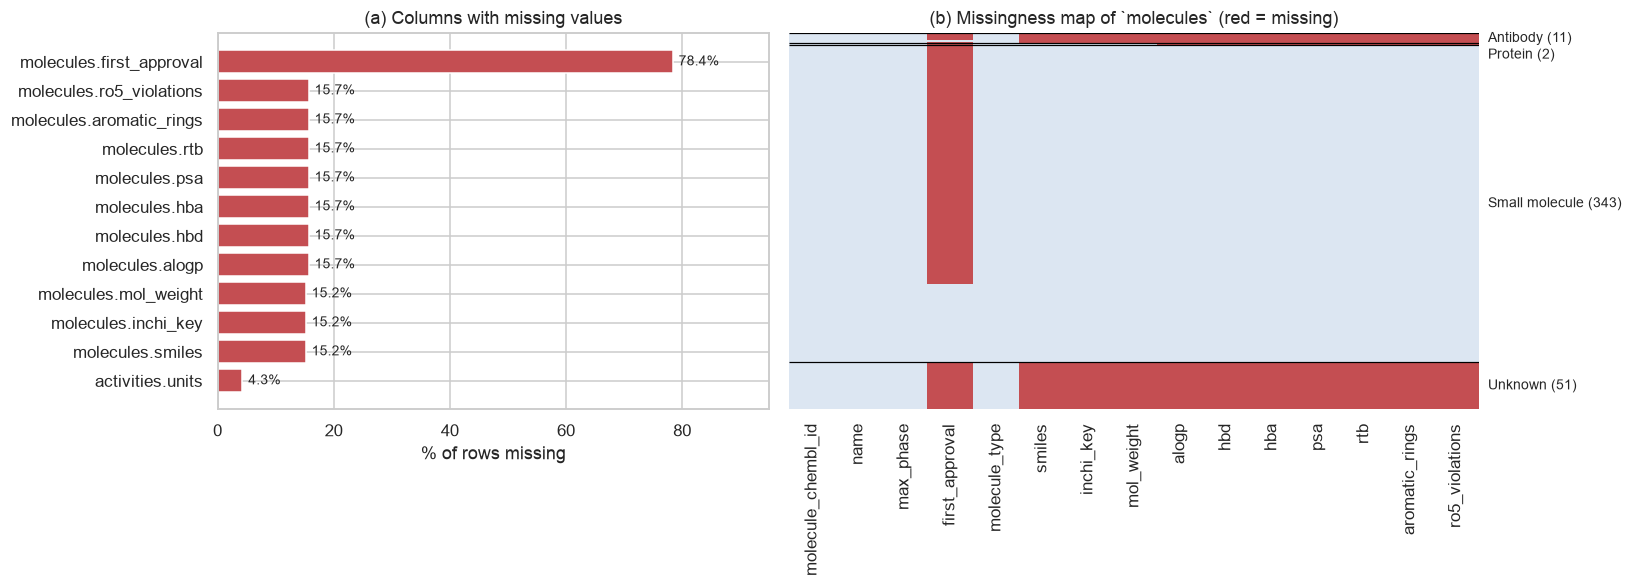

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})

# (a) percentage per affected column
m = with_missing.copy(); m["label"] = m.dataset + "." + m.column
m = m.sort_values("pct_missing")
axes[0].barh(m.label, m.pct_missing, color="#C44E52")
for y, v in enumerate(m.pct_missing):
    axes[0].text(v + 1, y, f"{v}%", va="center", fontsize=9)
axes[0].set_xlim(0, 95); axes[0].set_xlabel("% of rows missing"); axes[0].set_title("(a) Columns with missing values")

# (b) missingness map of molecules
order = mol.sort_values(["molecule_type", "max_phase"]).index
M = mol.loc[order].isna().astype(int)
sns.heatmap(M, cbar=False, yticklabels=False, cmap=ListedColormap(["#DCE6F2", "#C44E52"]), ax=axes[1])
sizes = mol.loc[order].groupby("molecule_type").size()      # same (alphabetical) order as the sort
pos, last_y = 0, None
for name, n in sizes.items():
    axes[1].hlines(pos, 0, M.shape[1], color="black", lw=0.8)
    y = pos + n / 2
    if last_y is not None and y - last_y < 18:      # keep the labels of thin bands readable
        y = last_y + 18
    axes[1].text(M.shape[1] + 0.2, y, f"{name} ({n})", va="center", fontsize=9)
    last_y = y; pos += n
axes[1].set_title("(b) Missingness map of `molecules` (red = missing)")
plt.tight_layout(); plt.show()

**Conclusion 3.2**
- (a) There are three levels of missingness: `first_approval` (78%), the structure and descriptor columns (about 15–16%), and `activities.units` (4%).
- (b) In the map the missing values form **solid horizontal bands**, not scattered dots: the *Antibody* and *Unknown* molecules (top and bottom bands) are red across all the structure and descriptor columns, the 2 *Protein* entries are red only on the descriptor columns, and the 343 *Small molecule* rows are complete on those columns.
- The `first_approval` column is red for all the non-approved molecules and present for the approved ones (the last rows of each block).

### 3.3 Why are the values missing? (patterns)
We look for *patterns*: do the structure and descriptor columns go missing together, and how are `first_approval` and `units` related to other columns?

In [4]:
struct_cols = ["smiles", "inchi_key", "mol_weight", "alogp", "hbd", "hba", "psa", "rtb", "aromatic_rings", "ro5_violations"]

print("(1) Missing patterns over the 10 structure / descriptor columns (1 = missing):")
pattern = mol[struct_cols].isna().astype(int).astype(str).agg("".join, axis=1).value_counts()
display(pattern.rename_axis("pattern (smiles inchi mw alogp hbd hba psa rtb arom ro5)").to_frame("molecules"))

print("(2) Molecules without a complete structure, by type:")
no_struct = mol[mol[struct_cols].isna().any(axis=1)]
display(no_struct.molecule_type.value_counts().to_frame("molecules"))

print("(3) first_approval missing vs development phase:")
display(pd.crosstab(mol.max_phase.astype(int), mol.first_approval.isna().rename("first_approval missing")))
print("approved molecule without an approval year:", mol[(mol.max_phase == 4) & mol.first_approval.isna()][["name", "molecule_type"]].values.tolist())

print("(4) activities.units missing vs the raw measurement type:")
display(act[act.units.isna()].type.value_counts().to_frame("rows with empty units"))
print("max |raw value - pchembl_value| on those rows:", round((act[act.units.isna()].value - act[act.units.isna()].pchembl_value).abs().max(), 3))

(1) Missing patterns over the 10 structure / descriptor columns (1 = missing):


,molecules
pattern (smiles inchi mw alogp hbd hba psa rtb arom ro5),
0000000000,343
1111111111,62
0001111111,2


(2) Molecules without a complete structure, by type:


,molecules
molecule_type,
Unknown,51
Antibody,11
Protein,2


(3) first_approval missing vs development phase:


first_approval missing,False,True
max_phase,,
1,0,110
2,0,156
3,0,52
4,88,1


approved molecule without an approval year: [['ZANIDATAMAB', 'Antibody']]
(4) activities.units missing vs the raw measurement type:


,rows with empty units
type,
pKi,614
pIC50,36
pKd,13
pKd(app),12


max |raw value - pchembl_value| on those rows: 0.005


**Conclusion 3.3 — the missing values are structural, not random**
1. **Structure and descriptors:** only **three patterns** exist. 343 molecules are complete; **62 molecules are missing all 10 columns**; 2 molecules are missing only the 7 descriptors. The 62 are the 51 *Unknown* and 11 *Antibody* molecules (no small-molecule structure exists for them); the 2 are the *Protein* (peptide) entries, which have a SMILES and a weight but no other descriptors.
2. **`first_approval`:** it is missing for **all 318 molecules of phases 1–3** and present for 88 of the 89 approved ones. "Missing" simply means "not approved yet". The single exception is an approved antibody (zanidatamab), which is not a small molecule.
3. **`activities.units`:** the 675 empty values are exactly the measurements reported as p-values (pKi 614, pIC50 36, pKd 13, pKd(app) 12). For those rows the raw `value` equals the `pchembl_value` (maximum difference 0.005), i.e. it is not a concentration, so it has no unit.
4. **Consequence:** these gaps are not errors or random omissions, so **imputing them would be wrong** (a mean molecular weight for an antibody has no meaning). The right handling is to exclude the molecules that have no structure from the clustering, to treat an empty `first_approval` as "not approved", and to ignore the raw `units` column.

### 3.4 Output: missing values report
We add to each affected column its **nature** (why it is missing) and the **proposed handling**, and save the report as `data/reports/missing_values_report.csv`.

In [5]:
nature = {
 ("molecules", "first_approval"): ("Structural: only approved drugs have an approval year", "Keep as is (empty = not approved); metadata, not a clustering feature"),
 ("molecules", "smiles"):         ("Structural: no structure for 51 Unknown + 11 Antibody molecules", "Exclude molecules without structure (keep Small molecule only); do not impute"),
 ("molecules", "inchi_key"):      ("Structural: same 62 molecules as smiles", "Exclude with the molecules without structure"),
 ("molecules", "mol_weight"):     ("Structural: same 62 molecules as smiles", "Exclude; recompute on the parent structure for the kept molecules"),
 ("activities", "units"):         ("Structural: measurement reported as a p-value (pKi, pIC50, pKd)", "Do not use the raw units/value; use standard_value and pchembl_value"),
}
for c in ["alogp", "hbd", "hba", "psa", "rtb", "aromatic_rings", "ro5_violations"]:
    nature[("molecules", c)] = ("Structural: 62 molecules without structure + 2 peptides", "Exclude those molecules; recompute descriptors with RDKit (ro5_violations is dropped)")

report3 = with_missing.copy()
report3["nature"] = [nature[(d, c)][0] for d, c in zip(report3.dataset, report3.column)]
report3["proposed_handling"] = [nature[(d, c)][1] for d, c in zip(report3.dataset, report3.column)]
report3.to_csv(REPORT_DIR / "missing_values_report.csv", index=False, encoding="utf-8-sig")
print("saved:", REPORT_DIR / "missing_values_report.csv")
report3[["dataset", "column", "n_missing", "pct_missing", "nature", "proposed_handling"]]

saved: ../data/reports/missing_values_report.csv


,dataset,column,n_missing,pct_missing,nature,proposed_handling
0,molecules,first_approval,319,78.4,Structural: only approved drugs have an approval year,"Keep as is (empty = not approved); metadata, not a clust..."
1,molecules,smiles,62,15.2,Structural: no structure for 51 Unknown + 11 Antibody mo...,Exclude molecules without structure (keep Small molecule...
2,molecules,inchi_key,62,15.2,Structural: same 62 molecules as smiles,Exclude with the molecules without structure
3,molecules,mol_weight,62,15.2,Structural: same 62 molecules as smiles,Exclude; recompute on the parent structure for the kept ...
4,molecules,alogp,64,15.7,Structural: 62 molecules without structure + 2 peptides,Exclude those molecules; recompute descriptors with RDKi...
5,molecules,hbd,64,15.7,Structural: 62 molecules without structure + 2 peptides,Exclude those molecules; recompute descriptors with RDKi...
6,molecules,hba,64,15.7,Structural: 62 molecules without structure + 2 peptides,Exclude those molecules; recompute descriptors with RDKi...
7,molecules,psa,64,15.7,Structural: 62 molecules without structure + 2 peptides,Exclude those molecules; recompute descriptors with RDKi...
8,molecules,rtb,64,15.7,Structural: 62 molecules without structure + 2 peptides,Exclude those molecules; recompute descriptors with RDKi...
9,molecules,aromatic_rings,64,15.7,Structural: 62 molecules without structure + 2 peptides,Exclude those molecules; recompute descriptors with RDKi...


**Conclusion — Step 3**
Missing data affects only `molecules` (11 columns) and `activities` (1 column), and in every case it is **structural**. The main consequence for the project is that **62 of the 407 molecules cannot be clustered from their structure**, plus 2 peptides that are not small molecules. No imputation is needed or appropriate.

---
# Step 4 — Duplicate analysis
Objective: find exact duplicate rows, duplicate IDs, duplicate molecular structures (in `molecules`) and duplicate molecule–target records (depending on the nature of each table). A repeated key is not always an error: in `activities` the same molecule–target pair is *meant* to appear many times (several experiments), so for each check we say whether it is a **true duplicate** or a **repetition by design**.

### 4.1 Exact duplicate rows
A row is an exact duplicate if **every column** has the same value as another row. `duplicated()` flags the second and later copies.

In [6]:
exact = pd.DataFrame({
    "rows": {ds: len(df) for ds, df in files.items()},
    "redundant rows (extra copies)": {ds: int(df.duplicated().sum()) for ds, df in files.items()},
    "rows involved (all copies)": {ds: int(df.duplicated(keep=False).sum()) for ds, df in files.items()},
})
exact["distinct rows repeated"] = exact["rows involved (all copies)"] - exact["redundant rows (extra copies)"]
display(exact)

print("Examples in activities (identical in every column):")
display(act[act.duplicated(keep=False)].sort_values(["molecule_chembl_id", "assay_chembl_id"]).head(6))
print("Duplicated rows in mechanisms:")
display(mech[mech.duplicated(keep=False)].sort_values(["molecule_chembl_id", "target_chembl_id"]))

,rows,redundant rows (extra copies),rows involved (all copies),distinct rows repeated
molecules,407,0,0,0
activities,15655,80,124,44
indications,2864,1,2,1
mechanisms,610,7,14,7
targets,548,0,0,0


Examples in activities (identical in every column):


,assay_chembl_id,molecule_chembl_id,pchembl_value,standard_type,standard_units,standard_value,target_chembl_id,target_pref_name,type,units,value
654,CHEMBL5733738,CHEMBL1421,7.26,IC50,nM,55.0,CHEMBL4601,Protein-tyrosine kinase 6,IC50,nM,55.0
655,CHEMBL5733738,CHEMBL1421,7.26,IC50,nM,55.0,CHEMBL4601,Protein-tyrosine kinase 6,IC50,nM,55.0
13019,CHEMBL3887529,CHEMBL1873475,9.30,IC50,nM,0.5,CHEMBL5251,Tyrosine-protein kinase BTK,IC50,nM,0.5
13038,CHEMBL3887529,CHEMBL1873475,9.30,IC50,nM,0.5,CHEMBL5251,Tyrosine-protein kinase BTK,IC50,nM,0.5
13020,CHEMBL3887530,CHEMBL1873475,7.93,IC50,nM,11.7,CHEMBL2959,Tyrosine-protein kinase ITK/TSK,IC50,nM,11.7
13039,CHEMBL3887530,CHEMBL1873475,7.93,IC50,nM,11.7,CHEMBL2959,Tyrosine-protein kinase ITK/TSK,IC50,nM,11.7


Duplicated rows in mechanisms:


,action_type,max_phase,mechanism_of_action,molecule_chembl_id,target_chembl_id
103,INHIBITOR,4,Cyclin-dependent kinase 6 inhibitor,CHEMBL3894860,CHEMBL2508
114,INHIBITOR,4,Cyclin-dependent kinase 6 inhibitor,CHEMBL3894860,CHEMBL2508
451,INHIBITOR,4,Cyclin-dependent kinase 4 inhibitor,CHEMBL3894860,CHEMBL331
474,INHIBITOR,4,Cyclin-dependent kinase 4 inhibitor,CHEMBL3894860,CHEMBL331
517,INHIBITOR,2,Tyrosine-protein kinase BTK inhibitor,CHEMBL4163691,CHEMBL5251
537,INHIBITOR,2,Tyrosine-protein kinase BTK inhibitor,CHEMBL4163691,CHEMBL5251
271,INHIBITOR,2,PI3-kinase p110-delta subunit inhibitor,CHEMBL4297584,CHEMBL3130
314,INHIBITOR,2,PI3-kinase p110-delta subunit inhibitor,CHEMBL4297584,CHEMBL3130
358,INHIBITOR,2,PI3-kinase p110-gamma subunit inhibitor,CHEMBL4297584,CHEMBL3267
365,INHIBITOR,2,PI3-kinase p110-gamma subunit inhibitor,CHEMBL4297584,CHEMBL3267


**Conclusion 4.1**
- `molecules` and `targets` have **no** exact duplicate rows.
- `activities` has **80 redundant rows** (124 rows involved, i.e. 44 distinct measurements repeated, some more than twice). They are identical in every column (same assay, molecule, kinase and value), so they add no information and would bias any average of the potency.
- `mechanisms` has **7** redundant rows and `indications` **1**.
- These are true duplicates: they can be dropped safely.

### 4.2 Duplicate IDs
In the two reference tables (`molecules`, `targets`) the ChEMBL ID must be unique: it is the primary key. In the other three tables the IDs are foreign keys and repeat by design, so what must be checked there is the *combination* of columns (next sections).

In [7]:
id_checks = pd.DataFrame([
    {"dataset": "molecules", "column": "molecule_chembl_id", "role": "primary key", "duplicated IDs": int(mol.molecule_chembl_id.duplicated().sum())},
    {"dataset": "targets",   "column": "target_chembl_id",   "role": "primary key", "duplicated IDs": int(tgt.target_chembl_id.duplicated().sum())},
    {"dataset": "activities", "column": "molecule_chembl_id", "role": "foreign key (repeats by design)", "duplicated IDs": int(act.molecule_chembl_id.duplicated().sum())},
    {"dataset": "indications", "column": "molecule_chembl_id", "role": "foreign key (repeats by design)", "duplicated IDs": int(ind.molecule_chembl_id.duplicated().sum())},
    {"dataset": "mechanisms", "column": "molecule_chembl_id", "role": "foreign key (repeats by design)", "duplicated IDs": int(mech.molecule_chembl_id.duplicated().sum())},
])
id_checks

,dataset,column,role,duplicated IDs
0,molecules,molecule_chembl_id,primary key,0
1,targets,target_chembl_id,primary key,0
2,activities,molecule_chembl_id,foreign key (repeats by design),15393
3,indications,molecule_chembl_id,foreign key (repeats by design),2505
4,mechanisms,molecule_chembl_id,foreign key (repeats by design),203


**Conclusion 4.2**
`molecule_chembl_id` (molecules) and `target_chembl_id` (targets) are **unique**: no duplicate primary keys. The repeated IDs in the other tables are normal (one molecule has many measurements, indications or mechanisms) and are not duplicates.

### 4.3 Duplicate molecular structures (in `molecules`)
The same drug can be stored twice, for example as a free base and as a salt. We test four levels of strictness: the InChIKey, the SMILES, the name, and finally the **parent structure** (the largest fragment of the SMILES, neutralized, then compared by InChIKey). The last one needs RDKit.

In [8]:
from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize
RDLogger.DisableLog("rdApp.*")

nn = mol[mol.inchi_key.notna()]
struct_checks = pd.DataFrame({
    "check": ["InChIKey (non-missing rows)", "SMILES (non-missing rows)", "name (case-insensitive)"],
    "duplicates": [int(nn.inchi_key.duplicated().sum()), int(mol.smiles.dropna().duplicated().sum()), int(mol.name.str.upper().duplicated().sum())]})
display(struct_checks)
print("SMILES that contain several fragments (salt / solvent):", int(mol.smiles.fillna("").str.contains(r"\.").sum()))

lfc, unc = rdMolStandardize.LargestFragmentChooser(), rdMolStandardize.Uncharger()
small = mol[(mol.molecule_type == "Small molecule") & mol.smiles.notna()].copy()
small["parent_ik"] = small.smiles.apply(lambda s: Chem.MolToInchiKey(unc.uncharge(lfc.choose(Chem.MolFromSmiles(s)))))
small["n_fragments"] = small.smiles.str.count(r"\.") + 1

groups = small[small.parent_ik.duplicated(keep=False)].sort_values(["parent_ik", "n_fragments"]).copy()
n_dup_groups, n_dup_molecules = groups.parent_ik.nunique(), len(groups)
print(f"\nAfter keeping the parent structure: {n_dup_molecules} molecules share a structure, in {n_dup_groups} groups")
print("unique parent structures:", small.parent_ik.nunique(), "of", len(small), "small molecules")
conn = small.parent_ik.str[:14]
print("groups when only the connectivity block of the InChIKey is compared:", conn[conn.duplicated(keep=False)].nunique())

,check,duplicates
0,InChIKey (non-missing rows),0
1,SMILES (non-missing rows),0
2,name (case-insensitive),0


SMILES that contain several fragments (salt / solvent): 49

After keeping the parent structure: 42 molecules share a structure, in 21 groups
unique parent structures: 322 of 343 small molecules
groups when only the connectivity block of the InChIKey is compared: 22


**Conclusion 4.3 (first part)**
- By InChIKey, SMILES and name there are **0** duplicates: at first sight the table looks clean.
- But **49 SMILES contain a counter-ion or solvent**, and once these are removed, **42 molecules share a structure, in 21 groups**. The 343 small molecules therefore represent only **322 unique structures**.
- Comparing only the connectivity block of the InChIKey gives 22 groups: the extra one is a pair that differs in the isotope/stereo layer (see below). It is treated as two different molecules.

In [9]:
cnt = act.groupby("molecule_chembl_id").size()
groups["n_activity"] = groups.molecule_chembl_id.map(cnt).fillna(0).astype(int)
grp_table = (groups.groupby("parent_ik")
             .agg(members=("name", " | ".join),
                  phases=("max_phase", lambda s: " / ".join(str(int(x)) for x in s)),
                  activity_records=("n_activity", lambda s: " / ".join(map(str, s))))
             .reset_index(drop=True))
display(grp_table)

print("The pair that differs only in the isotope / stereo layer of the InChIKey:")
extra = small[conn.isin(conn[conn.duplicated(keep=False)]) & ~small.parent_ik.isin(groups.parent_ik)]
display(extra.sort_values("parent_ik")[["molecule_chembl_id", "name", "max_phase", "parent_ik"]])

,members,phases,activity_records
0,COBIMETINIB | COBIMETINIB FUMARATE,4 / 4,14 / 0
1,RITLECITINIB | RITLECITINIB TOSYLATE,4 / 4,42 / 0
2,QUIZARTINIB | QUIZARTINIB DIHYDROCHLORIDE,4 / 4,262 / 1
3,OCIFISERTIB | CFI-400945,2 / 2,7 / 0
4,FOSTAMATINIB | FOSTAMATINIB DISODIUM,4 / 4,23 / 1
5,GILTERITINIB | GILTERITINIB FUMARATE,4 / 4,117 / 0
6,PACRITINIB | PACRITINIB CITRATE,4 / 4,101 / 0
7,PEXIDARTINIB | PEXIDARTINIB HYDROCHLORIDE,4 / 4,21 / 0
8,FEDRATINIB | FEDRATINIB HYDROCHLORIDE,4 / 4,391 / 0
9,NERATINIB | NERATINIB MALEATE,4 / 4,143 / 0


The pair that differs only in the isotope / stereo layer of the InChIKey:


,molecule_chembl_id,name,max_phase,parent_ik
137,CHEMBL4594382,DEURUXOLITINIB PHOSPHATE,4.0,HFNKQEVNSGCOJV-FBXGHSCESA-N
124,CHEMBL1795071,RUXOLITINIB PHOSPHATE,4.0,HFNKQEVNSGCOJV-OAHLLOKOSA-N


**Conclusion 4.3 (the groups)**
- The 21 groups are free base + salt (e.g. cobimetinib and cobimetinib fumarate) or the same compound under a code name and its INN (CFI-400945 / ocifisertib).
- **36 of the 42 molecules are approved drugs**: this is why the "89 approved molecules" shrink to 67 unique approved small molecules once duplicates are merged.
- The pair ruxolitinib phosphate / deuruxolitinib phosphate has the same connectivity but a different isotope/stereo layer (deuterated version): we keep it as two molecules.

#### 4.3b Why duplicate structures matter for the other files
The biological records are attached to a ChEMBL ID, and each of the two duplicate forms has its own ID. If we merge the forms, their records must be merged too. We measure how many records are concerned and how they are split between the two forms.

In [10]:
dup_ids = set(groups.molecule_chembl_id)
impact = pd.DataFrame({"records attached to the 42 duplicate-group molecules": {
    "activities": int(act.molecule_chembl_id.isin(dup_ids).sum()),
    "indications": int(ind.molecule_chembl_id.isin(dup_ids).sum()),
    "mechanisms": int(mech.molecule_chembl_id.isin(dup_ids).sum())}})
display(impact)

has_act = groups.groupby("parent_ik").n_activity.apply(lambda s: int((s > 0).sum()))
print("groups where both forms have activity records:", int((has_act == 2).sum()))
print("groups where only one form has activity records:", int((has_act == 1).sum()))
print("groups where no form has activity records:", int((has_act == 0).sum()))

,records attached to the 42 duplicate-group molecules
activities,2462
indications,452
mechanisms,76


groups where both forms have activity records: 4
groups where only one form has activity records: 17
groups where no form has activity records: 0


**Conclusion 4.3b**
- The 42 duplicate-group molecules carry **2 462 activity**, **452 indication** and **76 mechanism** records.
- In **17 of the 21 groups only one form has activity records** (for example the free base has 42 records and its tosylate none), and in 4 groups both forms have some. So when the duplicates are merged, records must be **re-attached to the surviving molecule**; simply deleting the duplicate rows would lose biological data.

### 4.4 Duplicate molecule–target records (depending on the table)
The meaning of "duplicate" depends on the table:
- **`mechanisms`** — one row should describe one molecule acting on one target, so a repeated (molecule, target) pair is suspicious.
- **`indications`** — one row should be one molecule–disease pair, so we check (molecule, `efo_term`).
- **`activities`** — a molecule–target pair is *meant* to have several measurements (different assays, types), so we measure how repeated they are at the level (molecule, target, measurement type), which is the level at which they will have to be aggregated.

In [11]:
key = ["molecule_chembl_id", "target_chembl_id"]
mech_pair = mech[mech.duplicated(key, keep=False)].sort_values(key)
mech_exact = int(mech.duplicated().sum()); mech_pairs_rep = int(mech.duplicated(key).sum())
print(f"mechanisms: repeated (molecule, target) pairs = {mech_pairs_rep}, of which exact duplicate rows = {mech_exact}")
print("-> the pair that is repeated with DIFFERENT content:")
display(mech_pair[~mech_pair.duplicated(keep=False)])

ind_key = ["molecule_chembl_id", "efo_term"]
ind_rep = int(ind.duplicated(ind_key).sum()); ind_exact = int(ind.duplicated().sum())
print(f"\nindications: repeated (molecule, efo_term) = {ind_rep}, of which exact duplicate rows = {ind_exact}")
print("-> repeated with DIFFERENT phase or MeSH heading:")
d = ind[ind.duplicated(ind_key, keep=False)].sort_values(ind_key)
display(d[~d.duplicated(keep=False)])

mechanisms: repeated (molecule, target) pairs = 8, of which exact duplicate rows = 7
-> the pair that is repeated with DIFFERENT content:


,action_type,max_phase,mechanism_of_action,molecule_chembl_id,target_chembl_id
594,ANTAGONIST,2,Receptor tyrosine-protein kinase erbB-3 antagonist,CHEMBL3545071,CHEMBL5838
597,INHIBITOR,2,Receptor tyrosine-protein kinase erbB-3 inhibitor,CHEMBL3545071,CHEMBL5838



indications: repeated (molecule, efo_term) = 4, of which exact duplicate rows = 1
-> repeated with DIFFERENT phase or MeSH heading:


,efo_term,max_phase_for_ind,mesh_heading,molecule_chembl_id
142,lymphoid leukemia,3.0,"Leukemia, Lymphoid",CHEMBL1421
368,lymphoid leukemia,4.0,Precursor Cell Lymphoblastic Leukemia-Lymphoma,CHEMBL1421
316,B-cell acute lymphoblastic leukemia,3.0,"Leukemia, Biphenotypic, Acute",CHEMBL1642
389,B-cell acute lymphoblastic leukemia,4.0,Precursor Cell Lymphoblastic Leukemia-Lymphoma,CHEMBL1642
1332,neoplasm of mature B-cells,4.0,"Lymphoma, Non-Hodgkin",CHEMBL2216870
1548,neoplasm of mature B-cells,3.0,"Lymphoma, Follicular",CHEMBL2216870


In [12]:
g = act.groupby(["molecule_chembl_id", "target_chembl_id", "standard_type"]).size()
n_pairs = act.groupby(key).ngroups
n_multi_groups, n_multi_records = int((g > 1).sum()), int(g[g > 1].sum())
print("activities: distinct (molecule, target) pairs        :", n_pairs)
print("            distinct (molecule, target, type) groups :", len(g))
print("            groups with more than one measurement    :", n_multi_groups, f"({100 * n_multi_groups / len(g):.0f}% of the groups)")
print("            records inside those groups              :", n_multi_records, f"({100 * n_multi_records / len(act):.0f}% of all the records)")
print("            records per group: median", int(g.median()), "| max", int(g.max()))
bins = pd.cut(g, [0, 1, 2, 5, 10, 50, 500], labels=["1", "2", "3-5", "6-10", "11-50", ">50"])
display(bins.value_counts().sort_index().rename_axis("records per group").to_frame("groups"))

print("exact repeated measurements | same (assay, molecule, target):", int(act.duplicated(["assay_chembl_id", "molecule_chembl_id", "target_chembl_id"]).sum()),
      "| same + same type:", int(act.duplicated(["assay_chembl_id", "molecule_chembl_id", "target_chembl_id", "standard_type"]).sum()))

activities: distinct (molecule, target) pairs        : 6671
            distinct (molecule, target, type) groups : 7633
            groups with more than one measurement    : 2619 (34% of the groups)
            records inside those groups              : 10641 (68% of all the records)
            records per group: median 1 | max 204


,groups
records per group,
1,5014
2,1419
3-5,868
6-10,177
11-50,149
>50,6


exact repeated measurements | same (assay, molecule, target): 199 | same + same type: 171


**Conclusion 4.4**
- **`mechanisms`:** 8 repeated (molecule, target) pairs. **7 are exact duplicate rows** (to drop). The 8th is a **conflict**: the same molecule (a phase-2 compound) is recorded on the erbB-3 kinase both as *ANTAGONIST* and as *INHIBITOR* — two mechanisms for one pair, to review and keep as a note rather than to delete.
- **`indications`:** 4 repeated (molecule, `efo_term`) pairs: **1 exact duplicate** and 3 with a different development phase and MeSH heading (for instance "lymphoid leukemia" recorded in phase 3 and in phase 4 for the same molecule). These are different records mapping to the same EFO term, not errors; when analyzing diseases the highest phase should be kept.
- **`activities`:** the 15 655 records describe 6 671 (molecule, kinase) pairs and 7 633 (molecule, kinase, type) groups. **2 619 groups (34%) contain more than one measurement, holding 10 641 records (68% of the table)**, with up to 204 records in one group (median 1). This repetition is by design (different assays and publications), but it means the table **cannot be used as is**: it must be aggregated per (molecule, kinase, type), for example by the median pChEMBL value, so that heavily studied molecules do not dominate.

### 4.5 Output: duplicate report
One row per check, with its nature (true duplicate, by design, or to decide) and the proposed action. The counts are taken from the cells above. Saved as `data/reports/duplicate_report.csv`.

In [13]:
report4 = pd.DataFrame([
 ("D1", "activities", "Exact duplicate rows", "all columns", int(act.duplicated().sum()), "True duplicate", "Drop the redundant copies"),
 ("D2", "mechanisms", "Exact duplicate rows", "all columns", mech_exact, "True duplicate", "Drop the redundant copies"),
 ("D3", "indications", "Exact duplicate rows", "all columns", ind_exact, "True duplicate", "Drop the redundant copy"),
 ("D4", "molecules / targets", "Exact duplicate rows", "all columns", 0, "None found", "-"),
 ("D5", "molecules / targets", "Duplicate primary IDs", "molecule_chembl_id / target_chembl_id", 0, "None found", "-"),
 ("D6", "molecules", "Duplicate InChIKey, SMILES or name", "inchi_key / smiles / name", 0, "None found", "-"),
 ("D7", "molecules", "Duplicate parent structures (salt + base, code + INN)", "parent InChIKey", n_dup_groups, f"True duplicate ({n_dup_molecules} molecules in {n_dup_groups} groups)", "Keep the largest fragment, deduplicate on the parent InChIKey, merge the records of both forms"),
 ("D8", "mechanisms", "Same (molecule, target) with conflicting action type", "molecule + target", mech_pairs_rep - mech_exact, "Conflict to review", "Keep and flag; do not delete automatically"),
 ("D9", "indications", "Same (molecule, EFO term) with different phase / MeSH", "molecule + efo_term", ind_rep - ind_exact, "Repetition by design", "Keep the highest phase per disease when grouping"),
 ("D10", "activities", "Several measurements per (molecule, target, type)", "molecule + target + standard_type", n_multi_groups, f"By design ({n_multi_records} records, {100 * n_multi_records / len(act):.0f}% of the table)", "Aggregate per (molecule, target, type), e.g. median pChEMBL"),
], columns=["id", "dataset", "check", "key", "n_found", "nature", "proposed_action"])
report4.to_csv(REPORT_DIR / "duplicate_report.csv", index=False, encoding="utf-8-sig")
print("saved:", REPORT_DIR / "duplicate_report.csv")
report4

saved: ../data/reports/duplicate_report.csv


,id,dataset,check,key,n_found,nature,proposed_action
0,D1,activities,Exact duplicate rows,all columns,80,True duplicate,Drop the redundant copies
1,D2,mechanisms,Exact duplicate rows,all columns,7,True duplicate,Drop the redundant copies
2,D3,indications,Exact duplicate rows,all columns,1,True duplicate,Drop the redundant copy
3,D4,molecules / targets,Exact duplicate rows,all columns,0,None found,-
4,D5,molecules / targets,Duplicate primary IDs,molecule_chembl_id / target_chembl_id,0,None found,-
5,D6,molecules,"Duplicate InChIKey, SMILES or name",inchi_key / smiles / name,0,None found,-
6,D7,molecules,"Duplicate parent structures (salt + base, code + INN)",parent InChIKey,21,True duplicate (42 molecules in 21 groups),"Keep the largest fragment, deduplicate on the parent InC..."
7,D8,mechanisms,"Same (molecule, target) with conflicting action type",molecule + target,1,Conflict to review,Keep and flag; do not delete automatically
8,D9,indications,"Same (molecule, EFO term) with different phase / MeSH",molecule + efo_term,3,Repetition by design,Keep the highest phase per disease when grouping
9,D10,activities,"Several measurements per (molecule, target, type)",molecule + target + standard_type,2619,"By design (10641 records, 68% of the table)","Aggregate per (molecule, target, type), e.g. median pChEMBL"


**Conclusion — Step 4**
- **True duplicates** exist in three places: `activities` (80 rows), `mechanisms` (7 rows) and `indications` (1 row), plus the **21 groups of duplicate structures** in `molecules` that the IDs and InChIKeys do not reveal.
- The structure duplicates are the most important: they change the number of molecules (343 → 322; approved 85 → 67) and split biological records across two IDs.
- The repetition in `activities` is by design but very large (68% of the records belong to repeated groups), so aggregation is mandatory before any biological interpretation.

---
# Step 5 — Invalid and inconsistent values
Objective: check unexpected values, incorrect data types, impossible numerical values, and inconsistent categories and units. For each check we count the violations; a result of 0 is also a result (the check passed).

### 5.1 Unexpected values
Three kinds of checks: (a) categorical columns only contain values from the allowed list (taken from the project's selection criteria and ChEMBL conventions), (b) identifiers follow their expected format, (c) text columns have no hidden whitespace or empty strings, and every SMILES can be read by RDKit.

In [14]:
allowed = {
 ("molecules", "molecule_type"):  {"Small molecule", "Antibody", "Protein", "Unknown"},
 ("molecules", "max_phase"):      {1.0, 2.0, 3.0, 4.0},
 ("activities", "standard_type"): {"IC50", "Ki", "Kd"},
 ("activities", "standard_units"): {"nM"},
 ("indications", "max_phase_for_ind"): {0.5, 1.0, 2.0, 3.0, 4.0},
 ("mechanisms", "action_type"):   {"INHIBITOR", "ANTAGONIST", "BLOCKER", "NEGATIVE ALLOSTERIC MODULATOR"},
 ("mechanisms", "max_phase"):     {1, 2, 3, 4},
 ("targets", "organism"):         {"Homo sapiens"},
 ("targets", "target_type"):      {"SINGLE PROTEIN"},
}
rows = []
for (ds, col), ok in allowed.items():
    s = files[ds][col].dropna()
    bad = s[~s.isin(ok)]
    rows.append({"check": "allowed values", "dataset": ds, "column": col, "n_checked": len(s), "n_unexpected": len(bad),
                 "values found": ", ".join(map(str, sorted(s.unique(), key=str)))[:70]})

id_cols = {"molecules": ["molecule_chembl_id"], "activities": ["assay_chembl_id", "molecule_chembl_id", "target_chembl_id"],
           "indications": ["molecule_chembl_id"], "mechanisms": ["molecule_chembl_id", "target_chembl_id"], "targets": ["target_chembl_id"]}
for ds, cols in id_cols.items():
    for c in cols:
        s = files[ds][c].dropna().astype(str)
        rows.append({"check": "ID format ^CHEMBL<digits>$", "dataset": ds, "column": c, "n_checked": len(s),
                     "n_unexpected": int((~s.str.match(r"^CHEMBL\d+$")).sum()), "values found": ""})
ik = mol.inchi_key.dropna()
rows.append({"check": "InChIKey format (14-10-1 letters)", "dataset": "molecules", "column": "inchi_key", "n_checked": len(ik),
             "n_unexpected": int((~ik.str.match(r"^[A-Z]{14}-[A-Z]{10}-[A-Z]$")).sum()), "values found": ""})

ws = 0; chk = 0
for ds, df in files.items():
    for c in df.select_dtypes(exclude="number").columns:
        s = df[c].dropna().astype(str); chk += len(s)
        ws += int((s != s.str.strip()).sum() + (s.str.strip() == "").sum())
rows.append({"check": "leading/trailing spaces or empty strings", "dataset": "all", "column": "all text columns", "n_checked": chk, "n_unexpected": ws, "values found": ""})

smi = mol.smiles.dropna()
rows.append({"check": "SMILES readable by RDKit", "dataset": "molecules", "column": "smiles", "n_checked": len(smi),
             "n_unexpected": int(smi.apply(lambda s: Chem.MolFromSmiles(s) is None).sum()), "values found": ""})
unexpected = pd.DataFrame(rows)
display(unexpected)
print("total unexpected values found:", int(unexpected.n_unexpected.sum()))

,check,dataset,column,n_checked,n_unexpected,values found
0,allowed values,molecules,molecule_type,407,0,"Antibody, Protein, Small molecule, Unknown"
1,allowed values,molecules,max_phase,407,0,"1.0, 2.0, 3.0, 4.0"
2,allowed values,activities,standard_type,15655,0,"IC50, Kd, Ki"
3,allowed values,activities,standard_units,15655,0,nM
4,allowed values,indications,max_phase_for_ind,2864,0,"0.5, 1.0, 2.0, 3.0, 4.0"
5,allowed values,mechanisms,action_type,610,0,"ANTAGONIST, INHIBITOR, NEGATIVE ALLOSTERIC MODULATOR"
6,allowed values,mechanisms,max_phase,610,0,"1, 2, 3, 4"
7,allowed values,targets,organism,548,0,Homo sapiens
8,allowed values,targets,target_type,548,0,SINGLE PROTEIN
9,ID format ^CHEMBL<digits>$,molecules,molecule_chembl_id,407,0,


total unexpected values found: 0


**Conclusion 5.1**
- **All checks pass: 0 unexpected values.** Every categorical column contains only allowed values, every ID has the form `CHEMBL<number>`, every InChIKey has the standard format, no text value has hidden whitespace or is empty, and **all 345 SMILES are valid** for RDKit.
- Two things are valid but worth remembering: `molecule_type` contains the categories *Unknown* (51) and *Antibody* (11) that are not small molecules, and `mechanisms.action_type` is not purely INHIBITOR (607 rows): it also has 2 *NEGATIVE ALLOSTERIC MODULATOR* and 1 *ANTAGONIST* record.

### 5.2 Incorrect data types
Pandas stores a numeric column that contains missing values as `float64`, even when all the values are whole numbers (counts, years, phases). We check which float columns contain only whole numbers, whether any text column actually holds numbers, and whether the same variable has different types in different tables.

In [15]:
rows = []
for ds, df in files.items():
    for c in df.select_dtypes("number").columns:
        s = df[c].dropna()
        whole = bool((s % 1 == 0).all())
        rows.append({"dataset": ds, "column": c, "pandas_dtype": str(df[c].dtype),
                     "n_missing": int(df[c].isna().sum()), "only whole numbers": whole,
                     "stored as float but should be integer": whole and df[c].dtype.kind == "f"})
type_check = pd.DataFrame(rows)
display(type_check)

flag = type_check[type_check["stored as float but should be integer"]]
print("float columns that contain only whole numbers:", list(flag.dataset + "." + flag.column))

print("\nText columns that can actually be read as numbers:")
for ds, df in files.items():
    for c in df.select_dtypes(exclude="number").columns:
        share = pd.to_numeric(df[c], errors="coerce").notna().mean()
        if share > 0: print(" ", ds, c, f"{100 * share:.1f}%")
print("  (none)" if True else "")
print("\nmax_phase type by table: molecules =", mol.max_phase.dtype, "| mechanisms =", mech.max_phase.dtype)

,dataset,column,pandas_dtype,n_missing,only whole numbers,stored as float but should be integer
0,molecules,max_phase,float64,0,True,True
1,molecules,first_approval,float64,319,True,True
2,molecules,mol_weight,float64,62,False,False
3,molecules,alogp,float64,64,False,False
4,molecules,hbd,float64,64,True,True
5,molecules,hba,float64,64,True,True
6,molecules,psa,float64,64,False,False
7,molecules,rtb,float64,64,True,True
8,molecules,aromatic_rings,float64,64,True,True
9,molecules,ro5_violations,float64,64,True,True


float columns that contain only whole numbers: ['molecules.max_phase', 'molecules.first_approval', 'molecules.hbd', 'molecules.hba', 'molecules.rtb', 'molecules.aromatic_rings', 'molecules.ro5_violations']

Text columns that can actually be read as numbers:
  (none)

max_phase type by table: molecules = float64 | mechanisms = int64


**Conclusion 5.2**
- **7 columns of `molecules` are stored as `float64` although all their values are whole numbers**: `max_phase`, `first_approval`, `hbd`, `hba`, `rtb`, `aromatic_rings` and `ro5_violations`. The cause is the missing values (pandas cannot store NaN in a plain integer column). They are counts, years or phases, so after the molecules without structure are excluded they can be cast to integers (or to pandas' nullable `Int64`).
- `max_phase_for_ind` is correctly a float (it contains 0.5) and the potency columns of `activities` are correctly floats.
- No text column hides numbers, and the identifiers are correctly text.
- **Inconsistent types across tables:** `max_phase` is `float64` in `molecules` but `int64` in `mechanisms` (there it has no missing values). This is harmless but should be harmonized if the tables are merged.

### 5.3 Impossible numerical values
We test physical and logical rules: a molecular weight must be positive, counts cannot be negative, a pChEMBL value must be within a plausible range and consistent with the measured concentration, an approval year can only exist for an approved molecule, and so on. We also test consistency **between** columns and tables.

In [16]:
def n_bad(mask): return int(mask.sum())
rules = [
 ("molecules", "mol_weight", "must be > 0", n_bad(mol.mol_weight <= 0), mol.mol_weight.notna().sum()),
 ("molecules", "alogp", "plausible range -10 to 20", n_bad((mol.alogp < -10) | (mol.alogp > 20)), mol.alogp.notna().sum()),
 ("molecules", "psa", "must be >= 0", n_bad(mol.psa < 0), mol.psa.notna().sum()),
 ("molecules", "hbd, hba, rtb, aromatic_rings", "counts must be >= 0", n_bad((mol[["hbd", "hba", "rtb", "aromatic_rings"]] < 0).any(axis=1)), mol.alogp.notna().sum()),
 ("molecules", "max_phase", "must be 1 to 4", n_bad(~mol.max_phase.isin([1, 2, 3, 4])), len(mol)),
 ("molecules", "first_approval", "year between 1950 and 2026", n_bad((mol.first_approval < 1950) | (mol.first_approval > 2026)), mol.first_approval.notna().sum()),
 ("molecules", "first_approval vs max_phase", "a year must only exist for approved molecules", n_bad(mol.first_approval.notna() & (mol.max_phase < 4)), mol.first_approval.notna().sum()),
 ("molecules", "ro5_violations", "must be 0 to 4", n_bad(~mol.ro5_violations.dropna().isin([0, 1, 2, 3, 4])), mol.ro5_violations.notna().sum()),
 ("activities", "standard_value", "concentration must be > 0", n_bad(act.standard_value <= 0), len(act)),
 ("activities", "value", "raw value must be > 0", n_bad(act.value <= 0), len(act)),
 ("activities", "pchembl_value", "must be between 0 and 14", n_bad((act.pchembl_value <= 0) | (act.pchembl_value > 14)), len(act)),
 ("activities", "pchembl_value vs standard_value", "pChEMBL = 9 - log10(nM) within 0.01", n_bad((9 - np.log10(act.standard_value) - act.pchembl_value).abs() > 0.01), len(act)),
 ("indications", "max_phase_for_ind", "must be 0.5 to 4", n_bad(~ind.max_phase_for_ind.isin([0.5, 1, 2, 3, 4])), len(ind)),
 ("indications vs molecules", "max_phase_for_ind", "indication phase cannot exceed the molecule's max_phase",
    n_bad(ind.merge(mol[["molecule_chembl_id", "max_phase"]], on="molecule_chembl_id").pipe(lambda m: m.max_phase_for_ind > m.max_phase)), len(ind)),
 ("mechanisms", "max_phase", "must be 1 to 4", n_bad(~mech.max_phase.isin([1, 2, 3, 4])), len(mech)),
]
rule_table = pd.DataFrame(rules, columns=["dataset", "column", "rule", "n_violations", "n_checked"])
display(rule_table)
print("total violations:", int(rule_table.n_violations.sum()))

,dataset,column,rule,n_violations,n_checked
0,molecules,mol_weight,must be > 0,0,345
1,molecules,alogp,plausible range -10 to 20,0,343
2,molecules,psa,must be >= 0,0,343
3,molecules,"hbd, hba, rtb, aromatic_rings",counts must be >= 0,0,343
4,molecules,max_phase,must be 1 to 4,0,407
5,molecules,first_approval,year between 1950 and 2026,0,88
6,molecules,first_approval vs max_phase,a year must only exist for approved molecules,0,88
7,molecules,ro5_violations,must be 0 to 4,0,343
8,activities,standard_value,concentration must be > 0,0,15655
9,activities,value,raw value must be > 0,0,15655


total violations: 0


In [17]:
print("Values that are valid but worth knowing (not violations):")
print(" negative logP:", int((mol.alogp < 0).sum()), "molecule(s), min =", round(mol.alogp.min(), 2), "(a hydrophilic molecule: valid)")
print(" zero H-bond donors:", int((mol.hbd == 0).sum()), "| zero rotatable bonds:", int((mol.rtb == 0).sum()), "| zero aromatic rings:", int((mol.aromatic_rings == 0).sum()))
print(" molecular weight > 1500:", int((mol.mol_weight > 1500).sum()), "->", mol[mol.mol_weight > 1500][["name", "molecule_type", "mol_weight"]].values.tolist())
print(" approved molecule without an approval year:", int(((mol.max_phase == 4) & mol.first_approval.isna()).sum()))
print(" largest pchembl-vs-standard_value gap:", round(float((9 - np.log10(act.standard_value) - act.pchembl_value).abs().max()), 4), "(rounding)")

sm = mol.dropna(subset=["alogp"])
std_ro5 = (sm.mol_weight > 500).astype(int) + (sm.alogp > 5) + (sm.hbd > 5) + (sm.hba > 10)
ro5_mismatch = int((std_ro5 != sm.ro5_violations).sum())
print(f"\nro5_violations vs the standard four rules applied to ChEMBL's own descriptors: {ro5_mismatch} of {len(sm)} molecules differ")
display(pd.crosstab(std_ro5.rename("standard count"), sm.ro5_violations.rename("ChEMBL ro5_violations")))

Values that are valid but worth knowing (not violations):
 negative logP: 1 molecule(s), min = -2.87 (a hydrophilic molecule: valid)
 zero H-bond donors: 10 | zero rotatable bonds: 3 | zero aromatic rings: 3
 molecular weight > 1500: 2 -> [['BRIMAPITIDE, C-TERMINAL ACID', 'Protein', 3823.5], ['BRIMAPITIDE', 'Protein', 3822.51]]
 approved molecule without an approval year: 1
 largest pchembl-vs-standard_value gap: 0.0055 (rounding)

ro5_violations vs the standard four rules applied to ChEMBL's own descriptors: 21 of 343 molecules differ


ChEMBL ro5_violations,0.0,1.0,2.0,3.0
standard count,,,,
0,183,0,0,0
1,18,85,1,0
2,0,2,51,0
3,0,0,0,3


**Conclusion 5.3**
- **No impossible value is present**: all 15 rules give 0 violations. Notably, pChEMBL values are consistent with the measured concentration in every row (the largest gap is 0.0055, a rounding effect) and no indication reaches a phase higher than the molecule itself.
- Valid but unusual: one molecule has a negative logP (−2.9, a very hydrophilic compound); 10 molecules have no H-bond donor; **2 entries have a molecular weight above 1 500 (3 823)**, they are the *Protein* peptides, not small molecules.
- **One logical inconsistency:** an approved molecule without approval year (an antibody, irrelevant once only small molecules are kept).
- **`ro5_violations` is not consistent with the standard definition:** for 21 of 343 molecules ChEMBL's count differs from the count obtained by applying the four rules of five (MW > 500, logP > 5, HBD > 5, HBA > 10) to ChEMBL's own descriptor columns (we did not investigate the cause; ChEMBL may use other definitions). This column is dropped anyway because it is derived from other descriptors.

### 5.4 Inconsistent categories and units
Here the values are valid but written in several ways. We check (a) the units in `activities`: how many spellings, and whether each one converts to nM consistently; (b) the raw measurement types; (c) category spellings that differ only by case; and (d) consistency between tables.

In [18]:
# (a) units: spellings and conversion factor to nM
UNIT_TO_NM = {"nM": 1, "nmol/L": 1, "nmol": 1, "uM": 1e3, "umol/L": 1e3, "pM": 1e-3, "M": 1e9,
              "10^-5M": 1e4, "10^-7M": 1e2, "10^-8M": 1e1, "10^-9M": 1, "10^-10M": 0.1,
              "10'-6M": 1e3, "10'-7M": 1e2, "10'-10M": 0.1}
a = act.dropna(subset=["units"]).copy()
a["expected_nM"] = a.value * a.units.map(UNIT_TO_NM)
a["rel_error"] = (a.expected_nM - a.standard_value).abs() / a.standard_value
unit_table = (a.groupby("units").agg(rows=("value", "size"), factor_to_nM=("units", lambda s: UNIT_TO_NM[s.iloc[0]]),
                                     max_relative_error=("rel_error", "max"))
              .sort_values("rows", ascending=False))
display(unit_table)
unit_spellings = act.units.nunique()
print("distinct unit spellings:", unit_spellings, "| unknown spellings (no conversion defined):", int(a.units.map(UNIT_TO_NM).isna().sum()))
print("rows where value x factor differs from standard_value by more than 0.1%:", int((a.rel_error > 0.001).sum()))

,rows,factor_to_nM,max_relative_error
units,,,
nM,13678,1.000000e+00,1.503759e-04
uM,1085,1.000000e+03,2.196423e-16
nmol/L,153,1.000000e+00,0.000000e+00
umol/L,22,1.000000e+03,0.000000e+00
M,18,1.000000e+09,3.233476e-04
10^-7M,6,1.000000e+02,0.000000e+00
10^-5M,5,1.000000e+04,0.000000e+00
nmol,3,1.000000e+00,0.000000e+00
pM,3,1.000000e-03,0.000000e+00


distinct unit spellings: 15 | unknown spellings (no conversion defined): 0
rows where value x factor differs from standard_value by more than 0.1%: 0


In [19]:
# (b) raw measurement types vs standard type
print("raw `type` -> standard_type:")
display(pd.crosstab(act.type, act.standard_type))
t = act.type.dropna().drop_duplicates(); tn = t.str.lower()
print("raw type spellings:", act.type.nunique(), "| after lower-casing:", tn.nunique(), "| differing only by case:", t[tn.duplicated(keep=False)].tolist())

# (c) other categorical columns: same label written in several ways?
rows = []
for ds, col in [("molecules", "molecule_type"), ("activities", "standard_type"), ("activities", "target_pref_name"),
                ("indications", "efo_term"), ("indications", "mesh_heading"), ("mechanisms", "action_type"),
                ("mechanisms", "mechanism_of_action"), ("targets", "pref_name")]:
    s = files[ds][col].dropna().astype(str)
    rows.append({"dataset": ds, "column": col, "distinct": s.nunique(), "after strip + lower": s.str.strip().str.lower().nunique()})
case_check = pd.DataFrame(rows); case_check["inconsistent spellings"] = case_check.distinct - case_check["after strip + lower"]
display(case_check)
e = ind.efo_term.dropna().drop_duplicates(); en = e.str.lower()
print("efo_term spellings differing only by case:", e[en.duplicated(keep=False)].tolist())

raw `type` -> standard_type:


standard_type,IC50,Kd,Ki
type,,,
IC50,5591,0,0
KD,0,18,0
Kd,0,6679,0
Kd apparent,0,2357,0
Kd(app),0,14,0
Ki,0,0,310
Ki(app),0,0,11
pIC50,36,0,0
pKd,0,13,0


raw type spellings: 11 | after lower-casing: 10 | differing only by case: ['Kd', 'KD']


,dataset,column,distinct,after strip + lower,inconsistent spellings
0,molecules,molecule_type,4,4,0
1,activities,standard_type,3,3,0
2,activities,target_pref_name,381,381,0
3,indications,efo_term,495,494,1
4,indications,mesh_heading,362,362,0
5,mechanisms,action_type,3,3,0
6,mechanisms,mechanism_of_action,102,102,0
7,targets,pref_name,548,548,0


efo_term spellings differing only by case: ['myelofibrosis', 'Myelofibrosis']


In [20]:
# (d) consistency between tables
mm = act.merge(tgt[["target_chembl_id", "pref_name"]], on="target_chembl_id", how="left")
print("activities.target_pref_name different from targets.pref_name:", int((mm.target_pref_name != mm.pref_name).sum()), "of", len(mm))

mt = mol.set_index("molecule_chembl_id").molecule_type
scope = pd.DataFrame({
    "records": {"activities": len(act), "indications": len(ind), "mechanisms": len(mech)},
    "on small molecules": {"activities": int((act.molecule_chembl_id.map(mt) == "Small molecule").sum()),
                           "indications": int((ind.molecule_chembl_id.map(mt) == "Small molecule").sum()),
                           "mechanisms": int((mech.molecule_chembl_id.map(mt) == "Small molecule").sum())}})
scope["on other molecule types"] = scope.records - scope["on small molecules"]
scope

activities.target_pref_name different from targets.pref_name: 0 of 15655


,records,on small molecules,on other molecule types
activities,15655,15655,0
indications,2864,2640,224
mechanisms,610,538,72


**Conclusion 5.4**
- **Units:** the raw `units` column has **15 different spellings** (nM 13 678, uM 1 085, nmol/L 153, umol/L 22, M 18, and odd forms such as `10^-7M` or `10'-6M` with an apostrophe). Despite this, every spelling converts to nM with a single factor and **`standard_value` equals the raw value × factor for all rows** (within a 0.1% rounding tolerance): the standardization done by ChEMBL is reliable, and the raw `units` and `value` columns can be ignored.
- **Types:** the raw `type` has 11 spellings (`Kd`, `KD`, `Kd apparent`, `Kd(app)`, `pKi`, `Ki(app)`…) but all map consistently to the 3 standard types. The only pure spelling inconsistency is `Kd` vs `KD`. This does not matter if `standard_type` is used.
- **Categories:** only one pair of labels differs by case: the disease `efo_term` "myelofibrosis" / "Myelofibrosis". All the other categorical columns are consistent.
- **Between tables:** the kinase names in `activities` are identical to those in `targets` (0 differences). But annotations exist for molecules that will not be clustered: **224 indication records and 72 mechanism records** belong to antibodies, proteins or *Unknown* molecules (all 15 655 activity records are on small molecules). They will have to be filtered after the molecule selection.

### 5.5 Output: data quality issues report
We gather everything found in Steps 3, 4 and 5 into one table: the issue, where it is, how many records are affected, its severity and the proposed action for the preprocessing task. The counts come from the previous cells. Saved as `data/reports/data_quality_issues_report.csv`.

Severity: **High** = changes the molecules to cluster or biases the results; **Medium** = must be handled before the biological analysis; **Low** = cosmetic or irrelevant after other steps.

In [21]:
no_struct_n = int(mol.smiles.isna().sum()); n_protein = int((mol.molecule_type == "Protein").sum())
issues = pd.DataFrame([
 # id, step, dataset, columns, issue, n_affected, severity, proposed action
 ("Q1", 3, "molecules", "smiles, inchi_key, mol_weight, descriptors", "Molecules without structure (51 Unknown + 11 Antibody) and 2 peptides", no_struct_n + n_protein, "High", "Keep molecule_type == 'Small molecule'; do not impute"),
 ("Q2", 4, "molecules", "smiles / inchi_key", "Duplicate parent structures hidden by salts and solvents (21 groups)", n_dup_molecules, "High", "Keep the largest fragment, neutralize, deduplicate on the parent InChIKey; re-attach the records of the merged forms"),
 ("Q3", 5, "molecules", "mol_weight", "ChEMBL molecular weight includes the counter-ion / solvent of the 49 salt forms (the other descriptors are computed on the parent)", int(mol.smiles.fillna("").str.contains(r"\.").sum()), "High", "Recompute the molecular weight on the parent structure (and, for consistency, all descriptors with RDKit)"),
 ("Q4", 4, "activities", "all columns", "Exact duplicate rows", int(act.duplicated().sum()), "Medium", "Drop the redundant copies"),
 ("Q5", 4, "activities", "molecule, target, standard_type", "Several measurements per (molecule, kinase, type): 68% of the records", n_multi_records, "Medium", "Aggregate per (molecule, kinase, type), e.g. median pChEMBL; never mix IC50, Ki and Kd"),
 ("Q6", 5, "indications / mechanisms", "molecule_chembl_id", "Annotation records on molecules that will not be clustered (indications 224, mechanisms 72)", int(scope.loc[["indications", "mechanisms"], "on other molecule types"].sum()), "Medium", "Filter after the molecule selection"),
 ("Q7", 5, "activities", "units, value, type", "Raw columns with 15 unit spellings and 11 type spellings (conversions are consistent)", unit_spellings, "Medium", "Use standard_type, standard_value and pchembl_value only; drop the raw columns"),
 ("Q8", 4, "mechanisms", "all columns", "Exact duplicate rows", mech_exact, "Low", "Drop the redundant copies"),
 ("Q9", 4, "mechanisms", "molecule + target", "Same (molecule, target) recorded as ANTAGONIST and INHIBITOR", mech_pairs_rep - mech_exact, "Low", "Keep and flag for review"),
 ("Q10", 4, "indications", "all columns", "Exact duplicate row", ind_exact, "Low", "Drop the redundant copy"),
 ("Q11", 5, "mechanisms", "action_type", "Non-inhibitor mechanisms (2 negative allosteric modulators, 1 antagonist)", int((mech.action_type != "INHIBITOR").sum()), "Low", "Keep but flag; check at interpretation time"),
 ("Q12", 5, "molecules", "7 columns stored as float", "max_phase, first_approval, hbd, hba, rtb, aromatic_rings, ro5_violations hold whole numbers", int(flag.shape[0]), "Low", "Cast to integer (or Int64) after excluding the molecules without structure"),
 ("Q13", 5, "molecules", "ro5_violations", "Inconsistent with the standard four-rule count", ro5_mismatch, "Low", "Drop the column (derived from other descriptors)"),
 ("Q14", 5, "indications", "efo_term", "Spelling inconsistency (myelofibrosis / Myelofibrosis)", 1, "Low", "Normalize the case"),
 ("Q15", 3, "molecules", "first_approval", "78% missing: empty means not approved", int(mol.first_approval.isna().sum()), "Low", "Keep as metadata; not a clustering feature"),
 ("Q16", 3, "activities", "units", "Empty for p-value measurements", int(act.units.isna().sum()), "Low", "Ignore the raw column"),
 ("Q17", 5, "molecules", "first_approval", "Approved molecule without approval year (an antibody)", int(((mol.max_phase == 4) & mol.first_approval.isna()).sum()), "Low", "No action (not a small molecule)"),
], columns=["id", "step", "dataset", "columns", "issue", "n_affected", "severity", "proposed_action"])
issues.to_csv(REPORT_DIR / "data_quality_issues_report.csv", index=False, encoding="utf-8-sig")
print("saved:", REPORT_DIR / "data_quality_issues_report.csv")
display(issues)
print(issues.severity.value_counts().reindex(["High", "Medium", "Low"]).to_dict())

saved: ../data/reports/data_quality_issues_report.csv


,id,step,dataset,columns,issue,n_affected,severity,proposed_action
0,Q1,3,molecules,"smiles, inchi_key, mol_weight, descriptors",Molecules without structure (51 Unknown + 11 Antibody) a...,64,High,Keep molecule_type == 'Small molecule'; do not impute
1,Q2,4,molecules,smiles / inchi_key,Duplicate parent structures hidden by salts and solvents...,42,High,"Keep the largest fragment, neutralize, deduplicate on th..."
2,Q3,5,molecules,mol_weight,ChEMBL molecular weight includes the counter-ion / solve...,49,High,Recompute the molecular weight on the parent structure (...
3,Q4,4,activities,all columns,Exact duplicate rows,80,Medium,Drop the redundant copies
4,Q5,4,activities,"molecule, target, standard_type","Several measurements per (molecule, kinase, type): 68% o...",10641,Medium,"Aggregate per (molecule, kinase, type), e.g. median pChE..."
5,Q6,5,indications / mechanisms,molecule_chembl_id,Annotation records on molecules that will not be cluster...,296,Medium,Filter after the molecule selection
6,Q7,5,activities,"units, value, type",Raw columns with 15 unit spellings and 11 type spellings...,15,Medium,"Use standard_type, standard_value and pchembl_value only..."
7,Q8,4,mechanisms,all columns,Exact duplicate rows,7,Low,Drop the redundant copies
8,Q9,4,mechanisms,molecule + target,"Same (molecule, target) recorded as ANTAGONIST and INHIB...",1,Low,Keep and flag for review
9,Q10,4,indications,all columns,Exact duplicate row,1,Low,Drop the redundant copy


{'High': 3, 'Medium': 4, 'Low': 10}


In [22]:
passed = pd.DataFrame([
 ("Unexpected category values", "0 of 9 categorical columns"),
 ("ID format (CHEMBL + digits), InChIKey format", "0 violations"),
 ("Hidden whitespace / empty strings", "0"),
 ("SMILES readable by RDKit", "345 of 345"),
 ("Duplicate primary IDs, InChIKeys, SMILES, names", "0"),
 ("Impossible numerical values (15 rules)", "0 violations"),
 ("pChEMBL consistent with standard_value", "all rows (max gap 0.0055)"),
 ("Indication phase <= molecule phase", "all rows"),
 ("Kinase names consistent between activities and targets", "all rows"),
 ("Raw units convert consistently to nM", "all rows"),
], columns=["check passed", "result"])
passed

,check passed,result
0,Unexpected category values,0 of 9 categorical columns
1,"ID format (CHEMBL + digits), InChIKey format",0 violations
2,Hidden whitespace / empty strings,0
3,SMILES readable by RDKit,345 of 345
4,"Duplicate primary IDs, InChIKeys, SMILES, names",0
5,Impossible numerical values (15 rules),0 violations
6,pChEMBL consistent with standard_value,all rows (max gap 0.0055)
7,Indication phase <= molecule phase,all rows
8,Kinase names consistent between activities and targets,all rows
9,Raw units convert consistently to nM,all rows


**Conclusion — Step 5 and Phase 2**
- The data is **valid** (no unexpected value, no impossible number, no broken ID, all structures readable, pChEMBL consistent with concentrations) but **not clean**: the problems are about *what* the rows represent, not about wrong values.
- The report lists **17 issues**: **3 High**, **4 Medium** and **10 Low**.
  - **High:** the molecules that cannot be clustered (62 without structure + 2 peptides), the 21 hidden duplicate structures, and the molecular weight inflated by counter-ions for the 49 salt forms.
  - **Medium:** repeated activity records (80 exact duplicates and 68% of the records in repeated groups), annotations for molecules outside the clustering set, and the messy raw `units`/`type` columns.
  - **Low:** small cosmetic issues.
- Three reports are saved in `data/reports/`: `missing_values_report.csv` (Step 3), `duplicate_report.csv` (Step 4) and `data_quality_issues_report.csv` (Step 5).

*Next: Phase 3 — the content of the molecules (phases, descriptors, fingerprints and similarity) and of the biological files.*